### 1. 

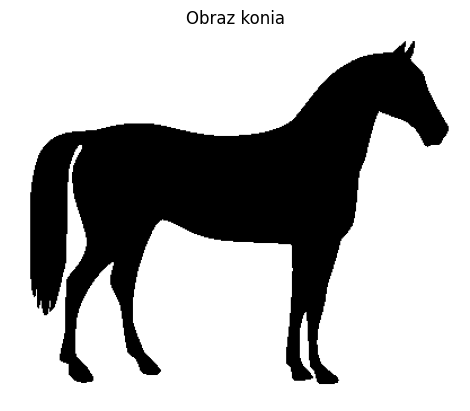

In [41]:
from skimage import io, data, color, exposure, img_as_float
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Wczytaj wybrany obraz
img = data.horse()

# Wyświetl obraz
plt.imshow(img, cmap="gray")
plt.title("Obraz konia")
plt.axis("off")
plt.show()


### 2. 

In [42]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())

Wymiary obrazu: (328, 400)
Typ danych: bool
Minimalna wartość: False
Maksymalna wartość: True


### 3.

In [43]:
print("Wymiary obrazu:", img.shape)
# Mamy dwa wymiary -> obraz w skali szarości

Wymiary obrazu: (328, 400)


### 4. 

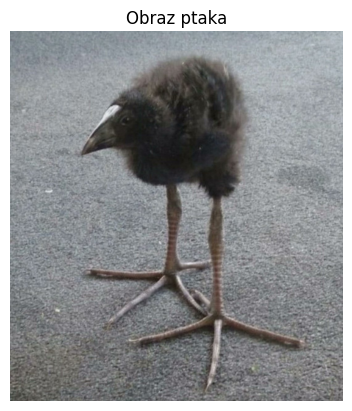

In [44]:
# Zmieniam obraz
img_path = "C:/Users/konio/programming/5sem_obrazy/lab1/ptak.jpg"
img = io.imread(img_path)
plt.imshow(img)
plt.title("Obraz ptaka")
plt.axis("off")
plt.show()

In [45]:
print("Wymiary obrazu:", img.shape)
print("Typ danych:", img.dtype)
print("Minimalna wartość:", img.min())
print("Maksymalna wartość:", img.max())

Wymiary obrazu: (1201, 1080, 3)
Typ danych: uint8
Minimalna wartość: 9
Maksymalna wartość: 240


In [46]:
img2 = Image.open("C:/Users/konio/programming/5sem_obrazy/lab1/ptak.jpg")
print(img2.getbands())

('R', 'G', 'B')


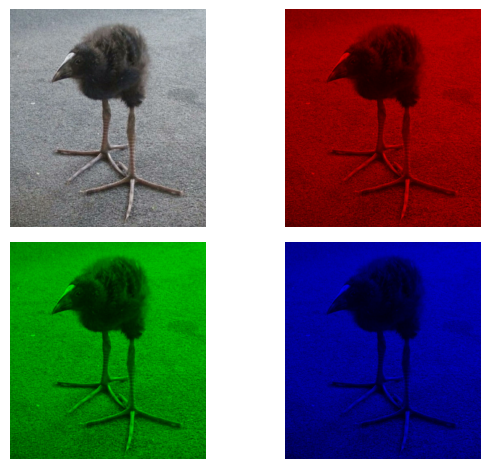

In [47]:
# Kanał czerwony
red = np.zeros_like(img)
red[:, :, 0] = img[:, :, 0] # wszystkie wiersze, wszystkie kolumny, pierwsza warstwa (zerowa)

green = np.zeros_like(img)
green[:, :, 1] = img[:, :, 1]

blue = np.zeros_like(img)
blue[:, :, 2] = img[:, :, 2]

figures, axes = plt.subplots(2, 2)

axes[0, 0].imshow(img, cmap="gray")
axes[0, 0].axis("off")
axes[0, 1].imshow(red, cmap="gray")
axes[0, 1].axis("off")
axes[1, 0].imshow(green, cmap="gray")
axes[1, 0].axis("off")
axes[1, 1].imshow(blue, cmap="gray")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

### 5. 

Wymiary obrazu: (1201, 1080)
Typ danych: float64
Minimalna wartość: 0.05432156862745098
Maksymalna wartość: 0.9269266666666668


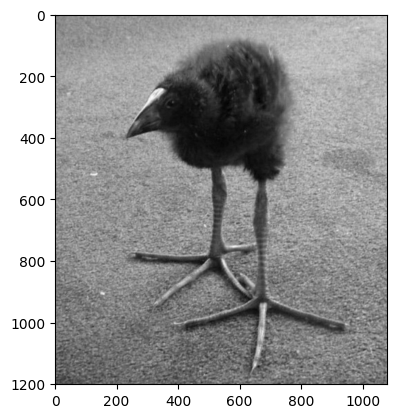

In [48]:
gray_img = color.rgb2gray(img)
print("Wymiary obrazu:", gray_img.shape)
print("Typ danych:", gray_img.dtype)
print("Minimalna wartość:", gray_img.min())
print("Maksymalna wartość:", gray_img.max())

plt.imshow(gray_img, cmap="gray")

### 6.

(0.0, 255.0)

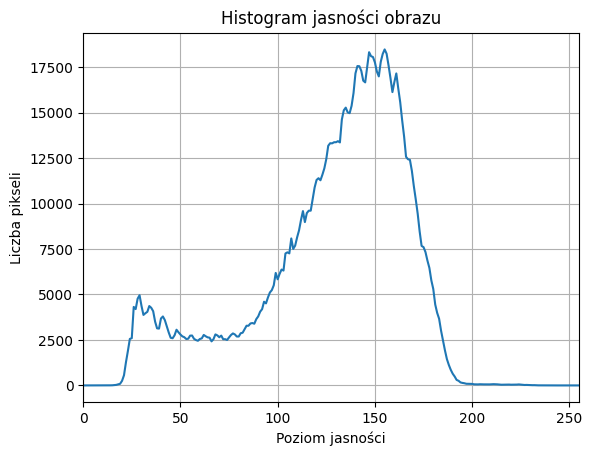

In [49]:
gray_8bit = (gray_img * 255).astype(np.uint8)

hist, bins = np.histogram(
    gray_8bit.flatten(),
    bins=256,
    range=(0, 256)
)

plt.plot(hist)
plt.title("Histogram jasności obrazu")
plt.xlabel("Poziom jasności")
plt.ylabel("Liczba pikseli")
plt.grid()
plt.xlim(0, 255)


### 7.

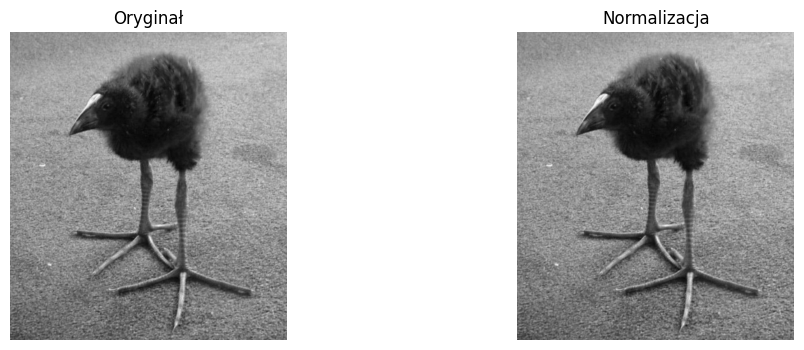

In [56]:
norm = exposure.rescale_intensity(gray_img, in_range="image", out_range=(0,1))
# zamiast in_range="image" mogłoby być też in_range=(min_val, max_val), "image" po prostu robi to za nas

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(gray_img, cmap="gray")
axes[0].axis("off")
axes[0].set_title("Oryginał")
axes[1].imshow(norm, cmap="gray")
axes[1].set_title("Normalizacja")
axes[1].axis("off")


plt.show()


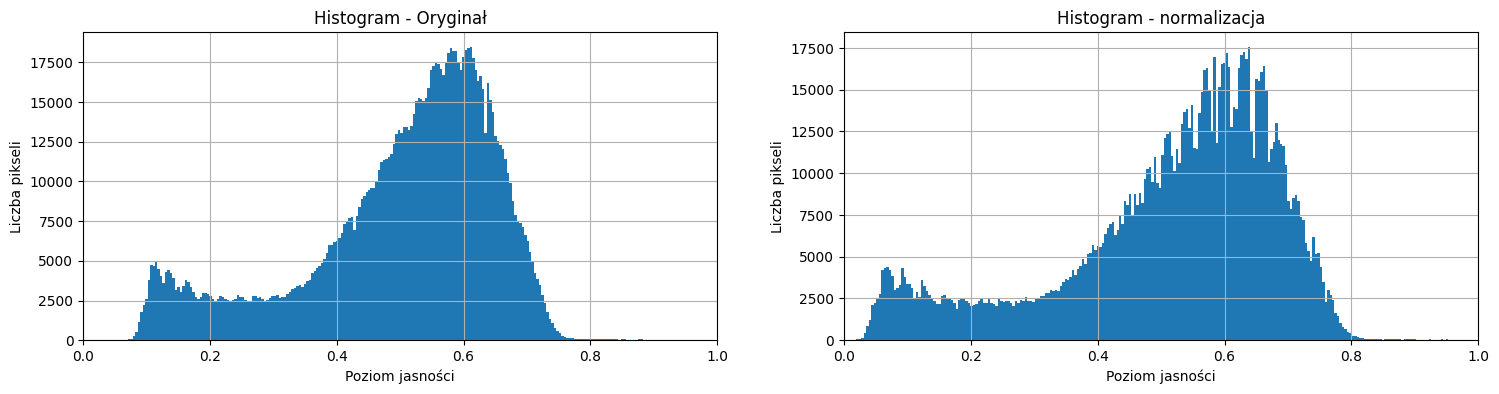

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4))

axes[0].hist(gray_img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

axes[1].hist(norm.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - normalizacja')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()

### 8.

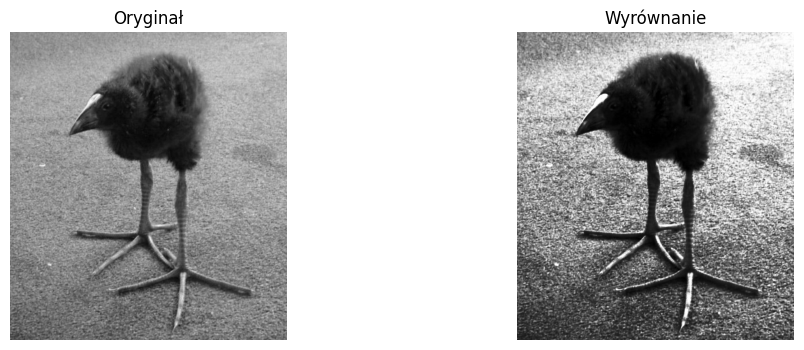

In [58]:
eq = exposure.equalize_hist(gray_img)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(gray_img, cmap="gray")
axes[0].axis("off")
axes[0].set_title("Oryginał")

axes[1].imshow(eq, cmap="gray")
axes[1].axis("off")
axes[1].set_title("Wyrównanie")

plt.show()

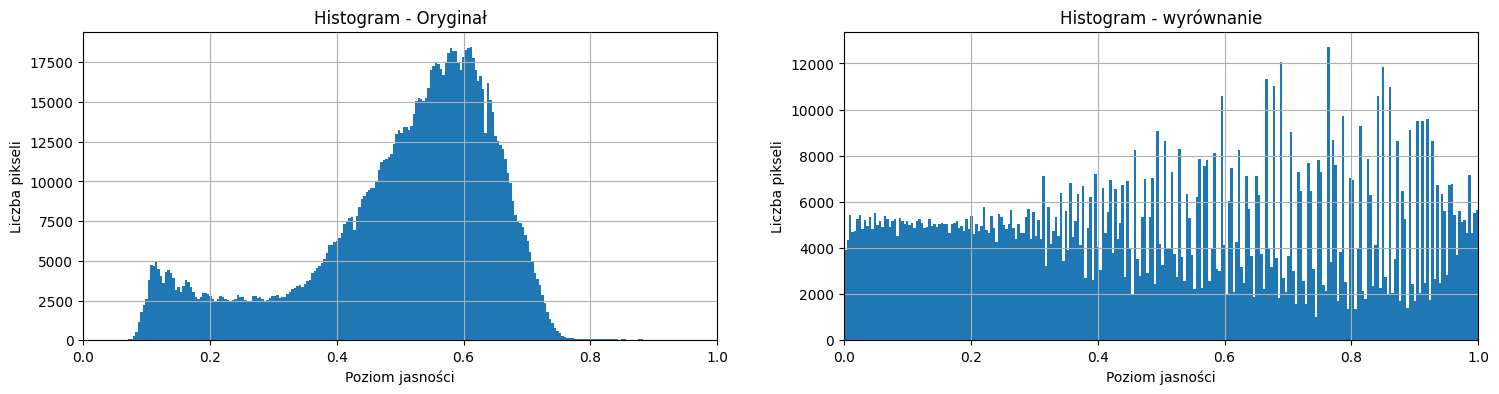

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4))

axes[0].hist(gray_img.ravel(), bins=256, range=(0, 1))
axes[0].set_title('Histogram - Oryginał')
axes[0].set_xlabel('Poziom jasności')
axes[0].set_ylabel('Liczba pikseli')
axes[0].set_xlim(0, 1)
axes[0].grid()

axes[1].hist(eq.ravel(), bins=256, range=(0, 1))
axes[1].set_title('Histogram - wyrównanie')
axes[1].set_xlabel('Poziom jasności')
axes[1].set_ylabel('Liczba pikseli')
axes[1].set_xlim(0, 1)
axes[1].grid()

### 9.